In [1]:
#Jeffrey Tam
#INST 414
#November 20, 2026
#Module 5

In [2]:
%matplotlib inline

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tqdm.notebook import tqdm

from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import train_test_split
from sklearn.tree import export_text

In [4]:
#original dataset
file_name = "diabetes_prediction_dataset.csv"
df = pd.read_csv(file_name)
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


In [5]:
#Remove all non possible user input, only known through medical testing
df = df.drop("HbA1c_level", axis=1)
df = df.drop("blood_glucose_level", axis=1)

#remove all no info data, since it can generate 
# df = df[df.smoking_history != "No Info"]

#Every feature will be used in the dataset, however smoking_history and gender needs to be normalized
# Since there are mutiple string values

# Get all unqiue values of smoking history
smoking_values_list = df["smoking_history"].values.tolist()
smoking_values = set(smoking_values_list)

smoking_values

{'No Info', 'current', 'ever', 'former', 'never', 'not current'}

In [6]:
#normalized dataframe of smoking history and gender
smoking_history_df = pd.get_dummies(df["smoking_history"]).replace({True: 1, False: 0})
gender_df = pd.get_dummies(df["gender"]).replace({True: 1, False: 0})

In [7]:
normalized_df = pd.concat([df, smoking_history_df], axis=1)
normalized_df = pd.concat([normalized_df, gender_df], axis=1)
normalized_df = normalized_df.drop("smoking_history", axis=1)
normalized_df = normalized_df.drop("gender", axis=1)

#Reorder columns
normalized_df = normalized_df.iloc[:, [0, 1, 2, 3, 5, 6, 7, 8, 9, 10, 11, 12, 4]]

print("Number of paients:", len(normalized_df))
normalized_df

Number of paients: 100000


,age,hypertension,heart_disease,bmi,No Info,current,ever,former,never,not current,Female,Male,diabetes
0,80.0,0,1,25.19,0,0,0,0,1,0,1,0,0
1,54.0,0,0,27.32,1,0,0,0,0,0,1,0,0
2,28.0,0,0,27.32,0,0,0,0,1,0,0,1,0
3,36.0,0,0,23.45,0,1,0,0,0,0,1,0,0
4,76.0,1,1,20.14,0,1,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,80.0,0,0,27.32,1,0,0,0,0,0,1,0,0
99996,2.0,0,0,17.37,1,0,0,0,0,0,1,0,0
99997,66.0,0,0,27.83,0,0,0,1,0,0,0,1,0
99998,24.0,0,0,35.42,0,0,0,0,1,0,1,0,0


In [8]:
#Training and Testing data
training_trails = int((len(normalized_df) * 0.8)) #80000

training_df = normalized_df.iloc[:training_trails,:]
testing_df = normalized_df.iloc[training_trails:,:]

y_train = training_df["diabetes"].values.tolist()
x_train = training_df.drop("diabetes", axis=1)

y_test = testing_df["diabetes"].values.tolist()
x_test = testing_df.drop("diabetes", axis=1)

print(x_train.shape, x_test.shape)

(80000, 12) (20000, 12)


In [9]:
#Accuracy
def accuracy(model, x, y):
    predicted_diabetes = model.predict(x)

    correct_diabetes = []

    for i in range(len(predicted_diabetes)):
        if predicted_diabetes[i] == y[i]:
            correct_diabetes.append(1)
        else: 
            correct_diabetes.append(0)
    return sum(correct_diabetes) / len(correct_diabetes)
    

In [10]:
#Recall and Percesion
def rec_per(model, x, y):
    predictions = model.predict(x)
    true_pos = 0
    false_neg = 0
    false_pos = 0

    for i in range(len(predictions)):
        #True Positive
        if (predictions[i] == 1) and y[i] == 1:
            true_pos += 1
        #False Negative
        elif (predictions[i] == 0) and y[i] == 1: 
            false_neg += 1
        #False Positive
        elif (predictions[i] == 1) and y[i] == 0:
            false_pos += 1
    
    recall = true_pos / (true_pos + false_neg)
    percesion = true_pos / (true_pos + false_pos)
    
    return recall, percesion

In [65]:
#Training Model
tree_rows = []

for depth in tqdm(range(1, 15)):
    model = DecisionTreeClassifier(max_depth=depth,
                                   class_weight="balanced",
                                   random_state=42)
    model.fit(x_train, y_train)

    train_accuracy = accuracy(model, x_train, y_train)
    test_accuracy = accuracy(model, x_test, y_test)

    
    training_recall, training_percesion = rec_per(model, x_train, y_train)
    test_recall, test_percesion = rec_per(model, x_test, y_test)
    
    tree_rows.append({
        "depth": depth, 
        "training_recall": training_recall,
        "training_percesion": training_percesion,
        "test_recall": test_recall,
        "test_percesion": test_percesion,
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
    })

  0%|          | 0/14 [00:00<?, ?it/s]

In [66]:
tree_df = pd.DataFrame(tree_rows)
tree_df

,depth,training_recall,training_percesion,test_recall,test_percesion,train_accuracy,test_accuracy
0,1,0.868699,0.155947,0.874105,0.152939,0.587738,0.58375
1,2,0.868699,0.155947,0.874105,0.152939,0.587738,0.58375
2,3,0.801436,0.181985,0.823986,0.182455,0.675775,0.67585
3,4,0.781506,0.198770,0.798926,0.196392,0.712650,0.70920
4,5,0.819314,0.190689,0.837709,0.189397,0.687975,0.68595
5,6,0.792644,0.207186,0.801313,0.204507,0.723588,0.72215
6,7,0.795721,0.210392,0.795943,0.205928,0.727838,0.72570
7,8,0.796600,0.216522,0.784606,0.207610,0.736775,0.73100
8,9,0.827521,0.210623,0.792959,0.197945,0.720738,0.71340
9,10,0.821366,0.222121,0.765513,0.203425,0.739400,0.72915


<Axes: title={'center': 'Recall and Percesion'}, xlabel='Depth', ylabel='value'>

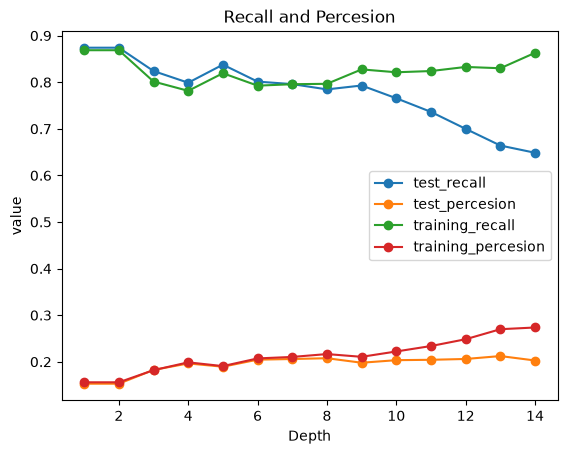

In [67]:
tree_df.plot(title="Recall and Percesion", x="depth", y=["test_recall", "test_percesion", "training_recall", "training_percesion"], marker="o", ylabel="ratio", xlabel="Depth")

<Axes: title={'center': 'Accuracy'}, xlabel='Depth', ylabel='accuracy'>

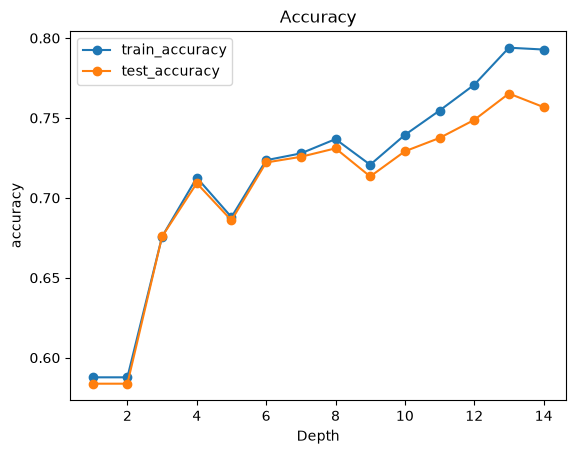

In [68]:
tree_df.plot(title="Accuracy", x="depth", y=["train_accuracy", "test_accuracy"], marker="o", ylabel="accuracy", xlabel="Depth")

In [76]:
#Best Max Depth is 7
model = DecisionTreeClassifier(max_depth=7,
                                class_weight="balanced",
                                random_state=42)

model = model.fit(x_train, y_train)

training_recall, training_percesion = rec_per(model, x_train, y_train)
test_recall, test_percesion = rec_per(model, x_test, y_test)

print("Train recall:\t", f"{training_recall:.2%}")
print("Test recall:\t", f"{test_recall:.2%}")
print("Train percesion:", f"{training_percesion:.2%}")
print("Test percesion:\t", f"{test_percesion:.2%}")

Train recall:	 79.57%
Test recall:	 79.59%
Train percesion: 21.04%
Test percesion:	 20.59%


In [77]:
#Finding samples model gotten wrong in testing
predicted_test_diabetes = model.predict(x_test)

index_errors = []
for i in range(len(predicted_test_diabetes)):
    
    if predicted_test_diabetes[i] != y_test[i]:    
        index_errors.append(i)

#Empty copy of the testing df
err_df = testing_df.iloc[0:0]

#Finding every patient in the testing df that the model predicted wrong 
for i in range(len(index_errors)):
    row_locate = testing_df.iloc[[index_errors[i]]]
    err_df = pd.concat([err_df, row_locate])
err_df.head()

,age,hypertension,heart_disease,bmi,No Info,current,ever,former,never,not current,Female,Male,diabetes
80006,80.0,0,0,24.23,0,0,0,0,1,0,1,0,0
80007,75.0,0,0,31.01,0,1,0,0,0,0,0,1,0
80008,54.0,0,0,28.56,0,0,0,0,1,0,1,0,1
80012,52.0,0,0,39.57,0,0,0,0,1,0,1,0,0
80018,64.0,0,0,36.05,0,0,1,0,0,0,1,0,0


In [79]:
#Constrcut a Decesion Tree
column_names = normalized_df.columns.tolist()
column_names.remove("diabetes")

read = export_text(
        model,
        feature_names=column_names,
        class_names=["Negative", "Positive"],
        spacing=2
    )

print(read)

|-- age <= 44.50
|  |-- bmi <= 31.41
|  |  |-- age <= 37.50
|  |  |  |-- No Info <= 0.50
|  |  |  |  |-- hypertension <= 0.50
|  |  |  |  |  |-- current <= 0.50
|  |  |  |  |  |  |-- bmi <= 21.30
|  |  |  |  |  |  |  |-- class: Negative
|  |  |  |  |  |  |-- bmi >  21.30
|  |  |  |  |  |  |  |-- class: Negative
|  |  |  |  |  |-- current >  0.50
|  |  |  |  |  |  |-- bmi <= 14.11
|  |  |  |  |  |  |  |-- class: Positive
|  |  |  |  |  |  |-- bmi >  14.11
|  |  |  |  |  |  |  |-- class: Negative
|  |  |  |  |-- hypertension >  0.50
|  |  |  |  |  |-- age <= 25.50
|  |  |  |  |  |  |-- class: Negative
|  |  |  |  |  |-- age >  25.50
|  |  |  |  |  |  |-- bmi <= 20.61
|  |  |  |  |  |  |  |-- class: Positive
|  |  |  |  |  |  |-- bmi >  20.61
|  |  |  |  |  |  |  |-- class: Positive
|  |  |  |-- No Info >  0.50
|  |  |  |  |-- age <= 9.50
|  |  |  |  |  |-- age <= 2.50
|  |  |  |  |  |  |-- class: Negative
|  |  |  |  |  |-- age >  2.50
|  |  |  |  |  |  |-- bmi <= 20.22
|  |  |  |  |  | 